In [1]:
import json
import polars as pl
import matplotlib.pyplot as plt

shape: (13, 7)
┌──────┬────────────────┬──────────────────┬──────────────────────┬────────────┬──────────────┬──────────────────┐
│ year ┆ red_light_mean ┆ red_light_months ┆ red_light_pct_change ┆ speed_mean ┆ speed_months ┆ speed_pct_change │
│ ---  ┆ ---            ┆ ---              ┆ ---                  ┆ ---        ┆ ---          ┆ ---              │
│ i32  ┆ f64            ┆ u32              ┆ f64                  ┆ f64        ┆ u32          ┆ f64              │
╞══════╪════════════════╪══════════════════╪══════════════════════╪════════════╪══════════════╪══════════════════╡
│ 2014 ┆ 5.1            ┆ 6                ┆ null                 ┆ 38.67      ┆ 6            ┆ null             │
│ 2015 ┆ 5.08           ┆ 12               ┆ -0.4                 ┆ 31.73      ┆ 12           ┆ -17.9            │
│ 2016 ┆ 6.52           ┆ 12               ┆ 28.3                 ┆ 28.64      ┆ 12           ┆ -9.7             │
│ 2017 ┆ 5.51           ┆ 12               ┆ -15.5               

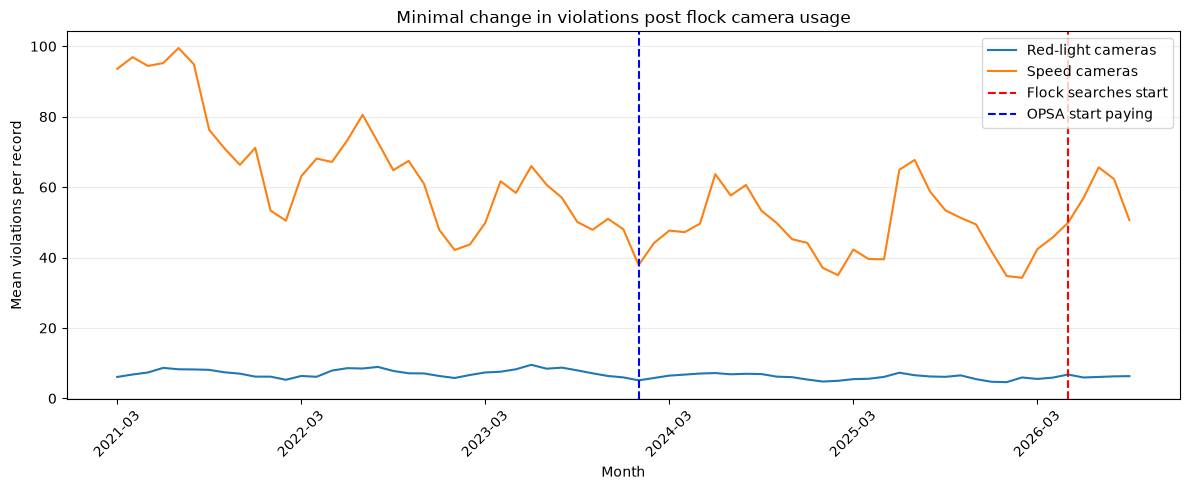

Red-light lowest: ('2026-01', 4.611635220125786) highest: ('2023-06', 9.534458509142054)
Speed-camera lowest: ('2026-02', 34.24656679151061) highest: ('2021-07', 99.4894451145959)


In [6]:
def yearly_violations(path, label):
    return (
        pl.read_csv(path, schema_overrides={"VIOLATIONS": pl.String})
        .select(
            pl.col("VIOLATION DATE").str.strptime(pl.Date, "%m/%d/%Y", strict=False).alias("date"),
            pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
        )
        .drop_nulls()
        .group_by(pl.col("date").dt.year().alias("year"))
        .agg(
            pl.col("violations").mean().round(2).alias(f"{label}_mean"),
            pl.col("date").dt.month().n_unique().alias(f"{label}_months"),
        )
        .sort("year")
        .with_columns(
            (pl.col(f"{label}_mean").pct_change() * 100).round(1).alias(f"{label}_pct_change")
        )
    )

red_yearly = yearly_violations("../red_light_100000.csv", "red_light")
speed_yearly = yearly_violations("../updatedSpeed.csv", "speed")

yearly_table = red_yearly.join(speed_yearly, on="year", how="full", coalesce=True).sort("year")

with pl.Config(tbl_rows=-1):
    print(yearly_table)



red_light = pl.read_csv("../red_light_100000.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().filter(pl.col("month") >= "2021-03").group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

speed_camera = pl.read_csv("../updatedSpeed.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().filter(pl.col("month") >= "2021-03").group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(red_light["month"], red_light["mean_violations"], label="Red-light cameras")
ax.plot(speed_camera["month"], speed_camera["mean_violations"], label="Speed cameras")
ax.set(title="Minimal change in violations post flock camera usage", xlabel="Month", ylabel="Mean violations per record")
ax.tick_params(axis="x", labelrotation=45)
ax.set_xticks(ax.get_xticks()[::12])
ax.grid(axis="y", alpha=0.25)
ax.axvline("2026-05", color="red", linestyle="--", linewidth=1.5, label="Flock searches start")
ax.axvline("2024-01", color="blue", linestyle="--", linewidth=1.5, label="OPSA start paying")
ax.legend()
fig.tight_layout()
plt.show()

for label, monthly_data in [("Red-light", red_light), ("Speed-camera", speed_camera)]:
    print(label, "lowest:", monthly_data.sort("mean_violations").row(0), "highest:", monthly_data.sort("mean_violations", descending=True).row(0))

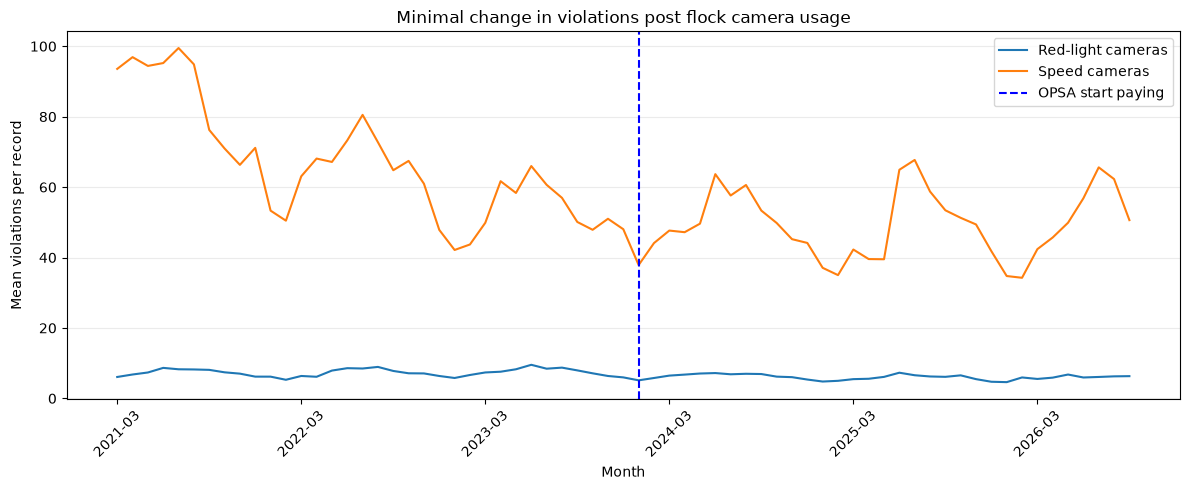

Red-light lowest: ('2026-01', 4.611635220125786) highest: ('2023-06', 9.534458509142054)
Speed-camera lowest: ('2026-02', 34.24656679151061) highest: ('2021-07', 99.4894451145959)


In [3]:
red_light = pl.read_csv("../red_light_100000.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().filter(pl.col("month") >= "2021-03").group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

speed_camera = pl.read_csv("../updatedSpeed.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().filter(pl.col("month") >= "2021-03").group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(red_light["month"], red_light["mean_violations"], label="Red-light cameras")
ax.plot(speed_camera["month"], speed_camera["mean_violations"], label="Speed cameras")
ax.set(title="Minimal change in violations post flock camera usage", xlabel="Month", ylabel="Mean violations per record")
ax.tick_params(axis="x", labelrotation=45)
ax.set_xticks(ax.get_xticks()[::12])
ax.grid(axis="y", alpha=0.25)
ax.axvline("2024-01", color="blue", linestyle="--", linewidth=1.5, label="OPSA start paying")
ax.legend()
fig.tight_layout()
plt.show()

for label, monthly_data in [("Red-light", red_light), ("Speed-camera", speed_camera)]:
    print(label, "lowest:", monthly_data.sort("mean_violations").row(0), "highest:", monthly_data.sort("mean_violations", descending=True).row(0))